### Alzheimer's Progression Prediction model 
##### via MRI image dataset from OASIS Alzheimer's dataset
---
Rudy Gamboa | Alex Hernandez | Jeff Ock

In [1]:
## Import modules
# for Data
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
# from tensorflow.keras.applications.mobilenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
# for Model
import tensorflow as tf
from tensorflow import keras
import tensorflow.keras                             # type: ignore
from tensorflow.keras.layers import Dense,Dropout   # type: ignore
from tensorflow.keras.applications import MobileNet # type: ignore
from tensorflow.keras.models import Model           # type: ignore
from tensorflow.keras.optimizers import Adam        # type: ignore
# for Other
import os

---
##### Get Data:
---

In [2]:
# Specify the path to the main data folder
cwd = os.getcwd()
train_path = os.path.join(cwd, "Reduced-Alzheimers-ADNI", "train")
test_path = os.path.join(cwd, "Reduced-Alzheimers-ADNI", "test")

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,  # Use a preprocessing function appropriate for your model (e.g., ResNet, Inception)
    zoom_range=0.1,  # Small zoom for slight variations
    rotation_range=3,  # Small rotations, as large rotations are not realistic for MRIs
    fill_mode='nearest',  # To handle pixels introduced during transformations
    horizontal_flip=True,  # Horizontal flipping is generally safe for brain MRIs
    vertical_flip=False,  # Avoid vertical flipping as it could distort anatomical structure
    validation_split=0.2  # 20% validation split
)

# Create train_generator iterator object
train_generator=train_datagen.flow_from_directory(train_path, 
                                                 target_size=(256,256),
                                                 color_mode='rgb',
                                                 batch_size= 16,
                                                 seed=1,
                                                 class_mode='categorical',
                                                 subset='training',
                                                 shuffle=True)   # set to False to show images in the same order for display

# Create train_generator iterator object
val_generator=train_datagen.flow_from_directory(train_path, 
                                                 target_size=(256,256),
                                                 color_mode='rgb',
                                                 batch_size= 16,
                                                 seed=1,
                                                 class_mode='categorical',
                                                 subset='validation',
                                                 shuffle=True)   # set to False to show images in the same order for display

# Test data generator
test_datagen = ImageDataGenerator(rescale=1./255)  # Only rescaling, no augmentation

# Test generator
test_generator = test_datagen.flow_from_directory(
    test_path, 
    target_size=(256, 256),
    color_mode='rgb',
    batch_size=16,
    seed=1,
    class_mode='categorical',
    shuffle=False  # Do not shuffle to keep predictions in order
)


Found 538 images belonging to 5 classes.
Found 134 images belonging to 5 classes.
Found 672 images belonging to 5 classes.


---
##### Data Exploration:
---

In [22]:
# Basic info
train_generator.__dict__.keys()

dict_keys(['image_data_generator', 'target_size', 'keep_aspect_ratio', 'color_mode', 'data_format', 'image_shape', 'save_to_dir', 'save_prefix', 'save_format', 'interpolation', 'split', 'subset', 'directory', 'classes', 'class_mode', 'dtype', 'samples', 'num_classes', 'class_indices', 'filenames', '_filepaths', 'n', 'batch_size', 'seed', 'shuffle', 'batch_index', 'total_batches_seen', 'lock', 'index_array', 'index_generator'])

In [23]:
train_generator.class_indices

{'Final AD JPEG': 0,
 'Final CN JPEG': 1,
 'Final EMCI JPEG': 2,
 'Final LMCI JPEG': 3,
 'Final MCI JPEG': 4}

In [24]:
train_generator.n

16200

In [25]:
# Baseline Accuracy
baseline_acc = 150/672
print(baseline_acc)

0.22321428571428573


Image example: Reduced AD


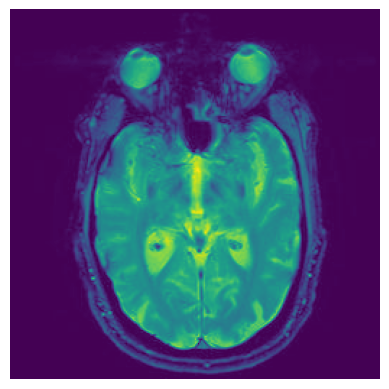

Image dimensions: (256, 256)
Number of channels: 3


In [42]:
# Get random image from Reduced AD
labels = os.listdir(train_path)
random_label = np.random.choice(labels)
random_img = np.random.choice((os.listdir(os.path.join(train_path, random_label))))
img_path = os.path.join(train_path, random_label, random_img)
img = plt.imread(img_path)

# Display the above image
print("Image example:", random_label)
plt.imshow(img)
plt.axis('off')
plt.show()

# Image info
print("Image dimensions:", img.shape[0:2])
print("Number of channels:", "3")

In [43]:
# Number of samples
print("Number of samples by class:")
for label in sorted(labels):
  print(f"- {label}: {len(os.listdir(os.path.join(train_path, label)))}")

Number of samples by class:
- Reduced AD: 150
- Reduced CN: 150
- Reduced EMCI: 150
- Reduced LMCI: 72
- Reduced MCI: 150


---
##### Data Curation:
---

In [ ]:
# code...

---
##### Data Augmentation / Feature Engineering:
---

In [ ]:
# code...

---
##### Final Data Visualization:
---

In [ ]:
# code...

---
##### Define Model:
---

In [3]:
# Base model, TBD
from tensorflow.keras.applications import MobileNet

base_model=MobileNet(weights='imagenet',
                     include_top=False, 
                     input_shape=(256,256,3))  # shape of RGB images
'''
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(256, 256, 3))
'''

# Modification of Base model
from tensorflow.keras import models
from tensorflow.keras import layers
# Define the L2 regularizer
from tensorflow.keras import regularizers
l2_reg = regularizers.l2(0.0001)  # You can adjust the regularization strength

# Build the model
model = models.Sequential()
model.add(base_model)
model.add(layers.Flatten())

# Add L2 regularization to the Dense layers
model.add(layers.Dense(1024, activation='relu', kernel_regularizer=l2_reg))
model.add(Dropout(0.5))
model.add(layers.Dense(1024, activation='relu', kernel_regularizer=l2_reg))
model.add(Dropout(0.5))
model.add(layers.Dense(512, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.Dense(5, activation='softmax'))  # Output layer (no regularization here)

C:\Users\jeffo_work\AppData\Local\Temp\ipykernel_16252\4261543048.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model=MobileNet(weights='imagenet',


In [30]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenet_1.00_224 (Functional) │ (None, 8, 8, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1024)           │    67,109,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,915,717 (274.34 MB)

 Trainable params: 71,893,829 (274.25 MB)

 Non-trainable params: 21,888 (85.50 KB)

---
##### Model Training:
---

In [64]:
# Check train generator
x, y = next(train_generator)
print("Train batch shapes:", x.shape, y.shape)
print("Sample labels:", y[:5])  # Print first few labels

# Check validation generator
x_val, y_val = next(val_generator)
print("Validation batch shapes:", x_val.shape, y_val.shape)
print("Sample validation labels:", y_val[:5])

Train batch shapes: (16, 256, 256, 3) (16, 5)
Sample labels: [[0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]]
Validation batch shapes: (16, 256, 256, 3) (16, 5)
Sample validation labels: [[0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]]


Epoch 1/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.5030 - loss: 1.2831 - val_accuracy: 0.2239 - val_loss: 4.8265
Epoch 2/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.5084 - loss: 1.0765 - val_accuracy: 0.1791 - val_loss: 8.2631
Epoch 3/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.4733 - loss: 1.0766 - val_accuracy: 0.2463 - val_loss: 4.9079
Epoch 4/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.4419 - loss: 1.2126 - val_accuracy: 0.2761 - val_loss: 2.8053
Epoch 5/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.5581 - loss: 1.0677 - val_accuracy: 0.2239 - val_loss: 15.4191
Epoch 6/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.4887 - loss: 1.1822 - val_accuracy: 0.2985 - val_loss: 1.6227
Epoch 7/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.5476 - loss: 1.0556 - val_accuracy: 0.3358 - val_loss: 2.5918
Epoch 8/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.5574 - loss: 1.1213 - val_accuracy: 0.2761 - val_loss

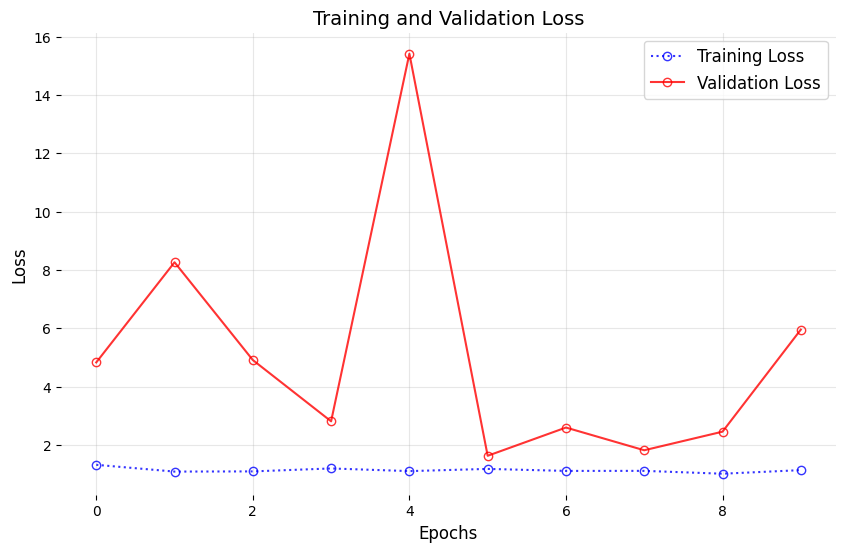

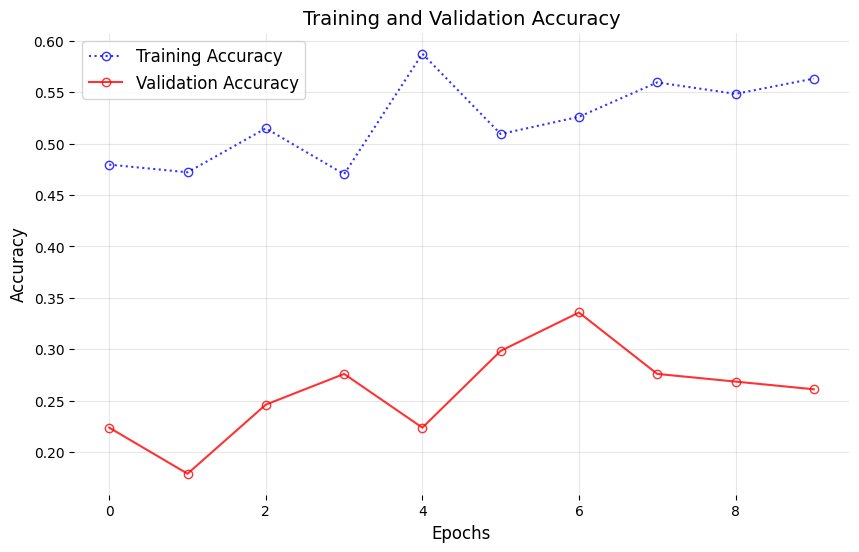

In [6]:
# Compile and run the model
model.compile(optimizer='Adam',loss='categorical_crossentropy',metrics=['accuracy'])

# Calculate step sizes
import math
step_size_train = math.ceil(train_generator.n / train_generator.batch_size) + 1
step_size_val = math.ceil(val_generator.n / val_generator.batch_size) + 1

# Reset generators at the beginning of each epoch
train_generator.reset()
val_generator.reset()

history = model.fit(
    train_generator,
    steps_per_epoch=step_size_train,
    epochs=10,
    validation_data=val_generator,
    validation_steps=step_size_val
)

# Plot Training and Validation Loss
plt.figure(figsize=(10, 6))
plt.plot(
    history.history['loss'],
    linestyle='dotted',
    color='blue',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Training Loss'
)
plt.plot(
    history.history['val_loss'],
    linestyle='solid',
    color='red',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Validation Loss'
)
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=12)

# Remove axes lines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)

# Add grid for reference
plt.grid(alpha=0.3)
plt.show()

# Plot Training and Validation Accuracy
plt.figure(figsize=(10, 6))
plt.plot(
    history.history['accuracy'],
    linestyle='dotted',
    color='blue',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Training Accuracy'
)
plt.plot(
    history.history['val_accuracy'],
    linestyle='solid',
    color='red',
    marker='o',
    markerfacecolor='none',  # Hollow circles
    markersize=6,
    alpha=0.8,
    label='Validation Accuracy'
)
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=12)

# Remove axes lines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)

# Add grid for reference
plt.grid(alpha=0.3)
plt.show()

34/34 ━━━━━━━━━━━━━━━━━━━━ 15s 421ms/step


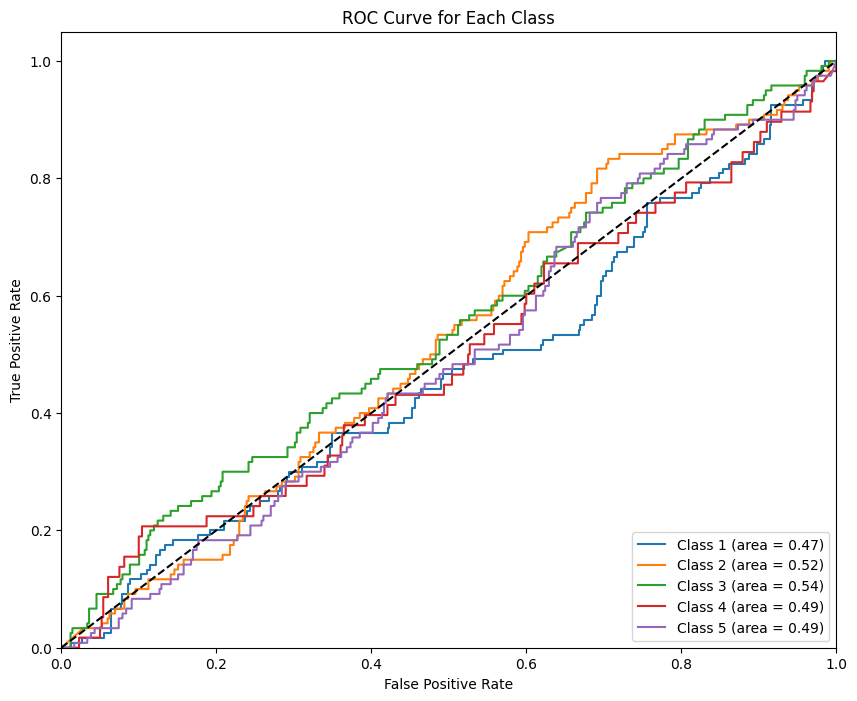

In [7]:
from sklearn.metrics import roc_curve, auc

# Get true labels and predicted probabilities
y_true = train_generator.classes  # True class labels
y_pred = model.predict(train_generator)  # Predicted probabilities for each class

# One-hot encode the true labels
from tensorflow.keras.utils import to_categorical
y_true_one_hot = to_categorical(y_true, num_classes=5)

# Plotting ROC for each class
fpr = {}
tpr = {}
roc_auc = {}

for i in range(5):  # Assuming 5 classes
    fpr[i], tpr[i], _ = roc_curve(y_true_one_hot[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(10, 8))
for i in range(5):
    plt.plot(fpr[i], tpr[i], label=f'Class {i+1} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Each Class')
plt.legend(loc="lower right")
plt.show()

---
##### Model Testing:
---

In [8]:
# Evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(test_generator, steps=test_generator.n // test_generator.batch_size + 1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

C:\Users\jeffo_work\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


43/43 ━━━━━━━━━━━━━━━━━━━━ 16s 359ms/step - accuracy: 0.2506 - loss: 31.5923
Test Loss: 30.2328
Test Accuracy: 0.2232


C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2032.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:158: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(value)


In [10]:
# Predict class probabilities
predictions = model.predict(test_generator)

# Convert probabilities to class labels
predicted_classes = predictions.argmax(axis=1)

# True class labels
true_classes = test_generator.classes

# Class labels
class_labels = list(test_generator.class_indices.keys())

# Display a classification report
from sklearn.metrics import classification_report

print(classification_report(true_classes, predicted_classes, target_names=class_labels))

42/42 ━━━━━━━━━━━━━━━━━━━━ 12s 291ms/step
              precision    recall  f1-score   support

  Reduced AD       0.00      0.00      0.00       150
  Reduced CN       0.22      1.00      0.36       150
Reduced EMCI       0.00      0.00      0.00       150
Reduced LMCI       0.00      0.00      0.00        72
 Reduced MCI       0.00      0.00      0.00       150

    accuracy                           0.22       672
   macro avg       0.04      0.20      0.07       672
weighted avg       0.05      0.22      0.08       672



C:\Users\jeffo_work\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\jeffo_work\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\jeffo_work\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\metric

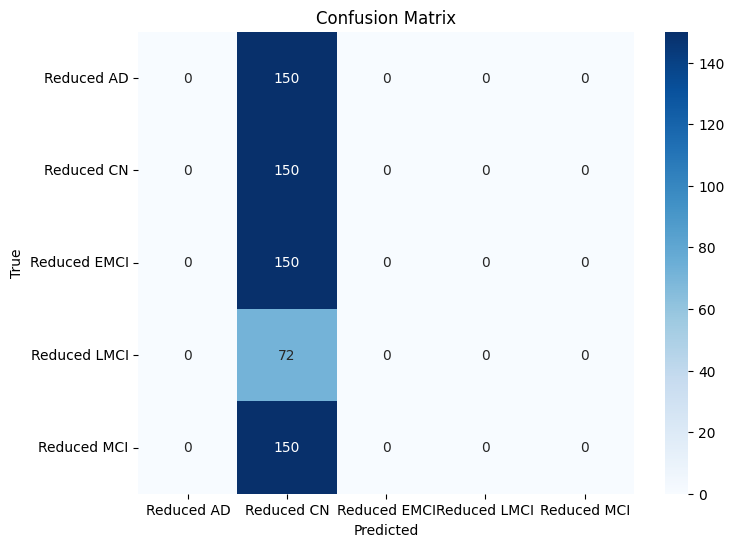

In [11]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

---
##### Final Results:
---

In [ ]:
# code...